# 회귀 실습 - 자전거 대여 수요 예측

데이터 세트 주요 칼럼

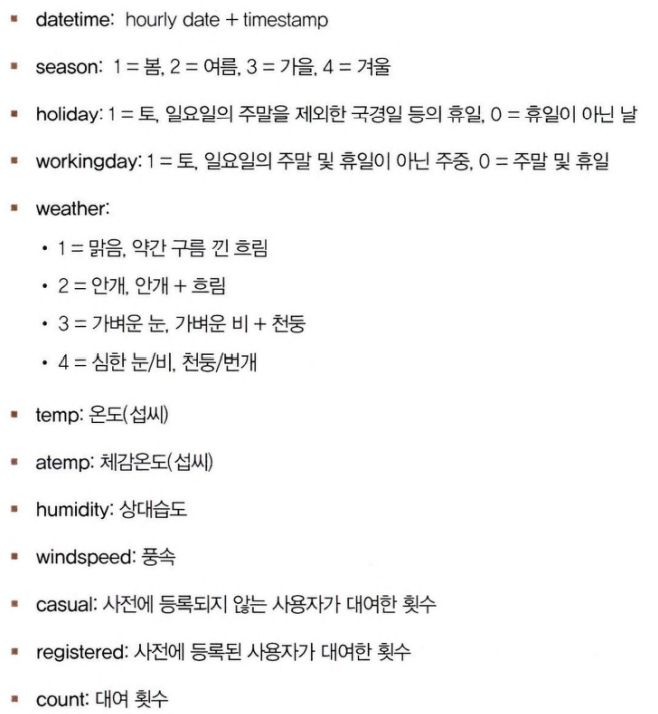

# **데이터 클렌징 및 가공과 데이터 시각화**

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline
import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)

bike_df = pd.read_csv('/content/train.csv')
print(bike_df.shape)
bike_df.head()

(10886, 12)


,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
0,2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0,3,13,16
1,2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0,8,32,40
2,2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0,5,27,32
3,2011-01-01 03:00:00,1,0,0,1,9.84,14.395,75,0.0,3,10,13
4,2011-01-01 04:00:00,1,0,0,1,9.84,14.395,75,0.0,0,1,1


In [2]:
bike_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10886 entries, 0 to 10885
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   datetime    10886 non-null  object 
 1   season      10886 non-null  int64  
 2   holiday     10886 non-null  int64  
 3   workingday  10886 non-null  int64  
 4   weather     10886 non-null  int64  
 5   temp        10886 non-null  float64
 6   atemp       10886 non-null  float64
 7   humidity    10886 non-null  int64  
 8   windspeed   10886 non-null  float64
 9   casual      10886 non-null  int64  
 10  registered  10886 non-null  int64  
 11  count       10886 non-null  int64  
dtypes: float64(3), int64(8), object(1)
memory usage: 1020.7+ KB


In [3]:
# 문자열을 datetime 타입으로 변경.
bike_df['datetime'] = bike_df.datetime.apply(pd.to_datetime)

# datetime 타입에서 년, 월, 일, 시간 추출
bike_df['year'] = bike_df.datetime.apply(lambda x : x.year)
bike_df['month'] = bike_df.datetime.apply(lambda x : x.month)
bike_df['day'] = bike_df.datetime.apply(lambda x : x.day)
bike_df['hour'] = bike_df.datetime.apply(lambda x: x.hour)
bike_df.head(3)

,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count,year,month,day,hour
0,2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0,3,13,16,2011,1,1,0
1,2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0,8,32,40,2011,1,1,1
2,2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0,5,27,32,2011,1,1,2


In [4]:
drop_columns = ['datetime', 'casual', 'registered']
bike_df.drop(drop_columns, axis=1, inplace=True)

주요 칼럼별로 Target 값인 count(대여 횟수)가 어떻게 분포되어 있는지 시각화
-  총 8개의 칼럼인 ‘year’, 'month’,’season’,’weather', ’day’, ‘hour’, ‘holiday’,’workingday’에 대해서 칼럼별 값에 따른 count의 합을 표현하기 위해서 시본의 barplot을 적용

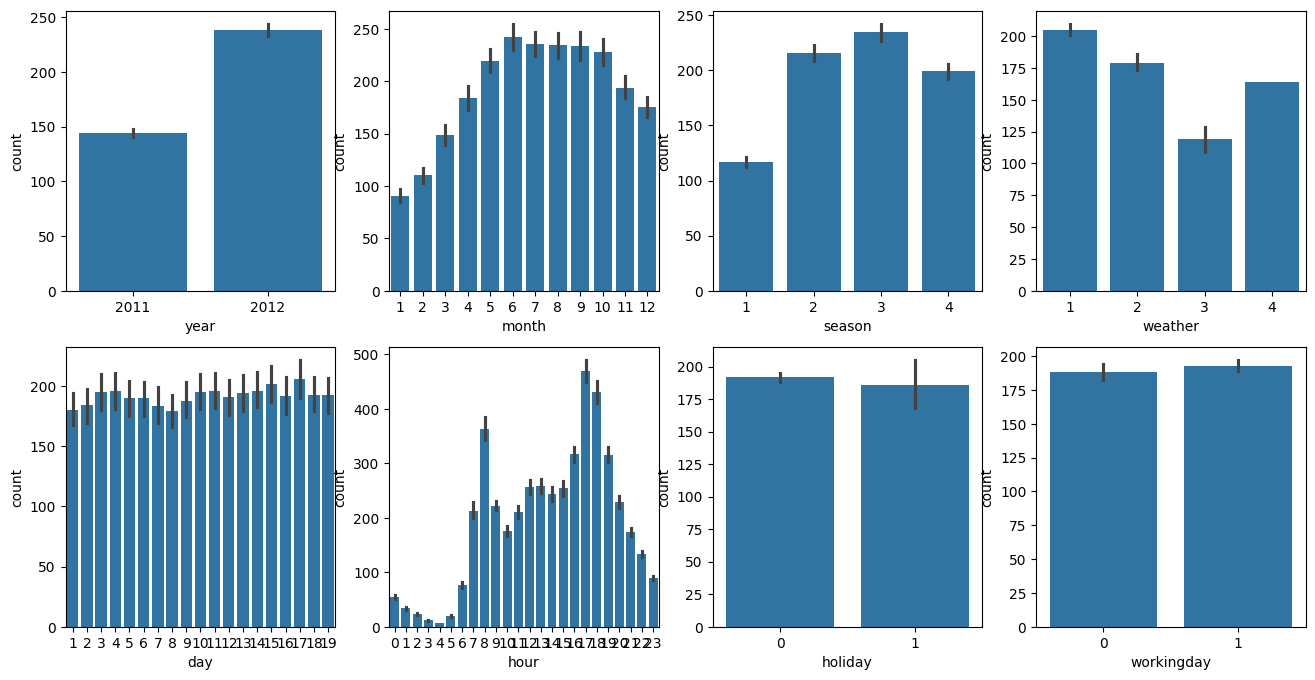

In [5]:
fig, axs = plt.subplots(figsize=(16, 8), ncols=4, nrows=2)
cat_features = ['year', 'month', 'season','weather', 'day', 'hour', 'holiday', 'workingday']
# cat_features에 있는 모든 칼럼별로 개별 칼럼값에 따른 count의 합을 barplot으로 시각화
for i, feature in enumerate(cat_features):
  row = int(i/4)
  col = i%4
  # 시본의 barplot을 이용해 칼럼값에 따른 count의 합을 표현
  sns.barplot(x=feature, y='count', data=bike_df, ax=axs[row][col])

year(년도)별 count를 보면 2012년이 2011 년보다 상대적으로 값이 높다
-  year 자체가 특별한 의미가 있어서라기보다는 시간이 지날수록 자전거 대여 횟수가 지속적으로 증가한 결과라고 여겨질수 있다

[다양한 회귀 모델을 데이터 세트에 적용해 예측 성능을 측정]

In [6]:
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np

# log 값 변환 시 NaN 등의 이슈로 log()가 아닌 log1p를 이용해 RMSLE 계산
def rmsle(y, pred):
    log_y = np.log1p(y)
    log_pred = np.log1p(pred)
    squared_error = (log_y - log_pred) ** 2
    rmsle_val = np.sqrt(np.mean(squared_error))
    return rmsle_val

# 사이킷런의 mean_squared_error()를 이용해 RMSE 계산
def rmse(y, pred):
    return np.sqrt(mean_squared_error(y, pred))

# MAE, RMSE, RMSLE를 모두 계산
def evaluate_regr(y, pred):
    rmsle_val = rmsle(y, pred)
    rmse_val = rmse(y, pred)
    # MAE는 사이킷런의 mean_absolute_error()로 계산
    mae_val = mean_absolute_error(y, pred)
    print('RMSLE: {0:.3f}, RMSE: {1:.3f}, MAE: {2:.3f}'.format(rmsle_val, rmse_val, mae_val))

rmsle() 함수를 만들 때 한 가지 주의해야 할 점
- rmsle를 구할 때 넘파이의 log() 함수를 이용하거나 사이킷런의 mean_squared_log_error()를 이용할 수도 있지만 데이터 값의 크기에 따라 오버플로/언더플로(overflowunderflow) 오류가 발생하기 쉽다

In [8]:
# 다음과 같은 rmsle 구현은 오버플로나 언더플로 오류를 발생하기 쉽습니다.
from sklearn.metrics import mean_squared_log_error
import numpy as np

def rmsle(y, pred):
  msle = mean_squared_log_error(y, pred)
  rmsle_val = np.sqrt(msle)
  return rmsle_val

** 따라서 log()보다는 loglp()를 이용하는데, loglp(x)의 경우는 log(l十X)로 변환되므로 X값이 0이
되더라도 log(O)인 무한대가 되지 않고, log(l)인 0이 되므로 오버플로/언더플로 문제를 해결해 준다
- 그리고 loglp()로 변환된 값은 다시 넘파이의 expml() 함수로 쉽게 원래의 스케일로 복원될 수
있다


# **로그 변환, 피처 인코딩과 모델 학습/예측/평가**

[ 회귀 모델을 이용해 자전거 대여 횟수를 예측 ]

회귀 모델을 적용하기 전에 데이터
세트에 대해서 먼저 처리해야 할 사항
- 결괏값이 정규 분포로 돼 있는지 확인하는
- 카테고리형 회귀 모델의 경우 원-핫 인코딩으로 피처를 인코딩

In [11]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LinearRegression, Ridge, Lasso

y_target = bike_df['count']
X_features = bike_df.drop(['count'], axis=1, inplace=False)
X_train, X_test, y_train, y_test = train_test_split(X_features, y_target, test_size=0.3,
random_state=0)

lr_reg = LinearRegression()
lr_reg.fit(X_train, y_train)

pred = lr_reg.predict(X_test)

# 예측값 중 음수가 발생할 경우를 대비하여 최소값을 0으로 보정
pred_clipped = np.clip(pred, 0, None)

evaluate_regr(y_test, pred_clipped)

RMSLE: 1.284, RMSE: 140.186, MAE: 104.193


실제 값과 예측값이 어느 정도 차이가 나는지
DataFrame의 칼럼으로 만들어서 오류 값이 가장 큰 순으로 5개만 확인

In [14]:
def get_top_error_data(y_test, pred, n_tops = 5):
  # DataFrame의 칼럼으로 실제 대여 횟수(count)와 예측값을 서로 비교할 수 있도록 생성.
  result_df = pd.DataFrame(y_test.values, columns=['real_count'])
  result_df['predicted_count' ]= np.round(pred)
  result_df['diff'] = np.abs(result_df['real_count'] - result_df['predicted_count'])

# 예측값과 실제 값이 가장 큰 데이터 순으로 출력.
  print(result_df.sort_values('diff', ascending=False)[:n_tops])

get_top_error_data(y_test, pred, n_tops=5)


      real_count  predicted_count   diff
1618         890            322.0  568.0
966          884            327.0  557.0
3151         798            241.0  557.0
412          745            194.0  551.0
2817         856            310.0  546.0


<Axes: >

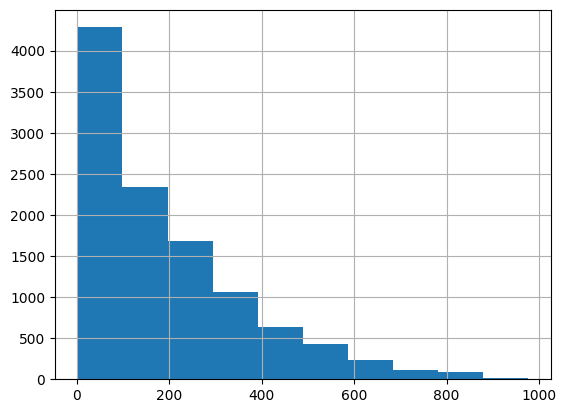

In [15]:
y_target.hist()

count 칼럼 값이 정규 분포가 아닌 0〜200 사이에 왜곡돼 있는 것을 알 수 있다

<Axes: >

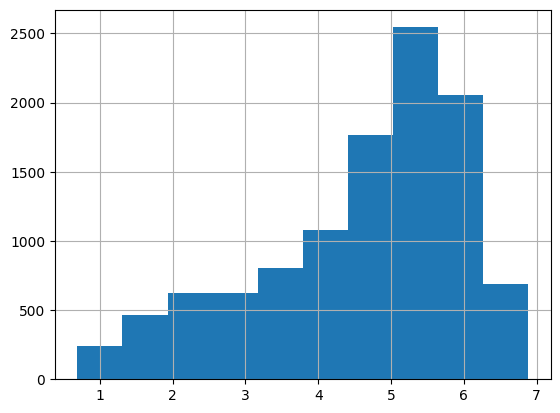

In [16]:
y_log_transform = np.log1p(y_target)
y_log_transform.hist()

In [19]:
# 타깃 칼럼인 count 값을 loglp로 로그 변환
y_target_log = np.log1p(y_target)

# 로그 변환된 y_target_log를 반영해 학습/테스트 데이터 세트 분할
X_train, X_test, y_train, y_test = train_test_split(X_features, y_target_log, test_size=0.3,
random_state=0)

lr_reg = LinearRegression()
lr_reg.fit(X_train, y_train)
pred = lr_reg.predict(X_test)

# 테스트 데이터 세트의 Target 값은 로그 변환됐으므로 다시 expml을 이용해 원래 스케일로 변환
y_test_exp = np.expm1(y_test)

# 예측값 역시 로그 변환된 타깃 기반으로 학습돼 예측됐으므로 다시 expml로 스케일 변환
pred_exp = np.expm1(pred)
evaluate_regr(y_test_exp, pred_exp)


RMSLE: 1.017, RMSE: 162.594, MAE: 109.286


RMSLE 오류는 줄어들었지만, RMSE는 오히려 더 늘어났다

<Axes: ylabel='None'>

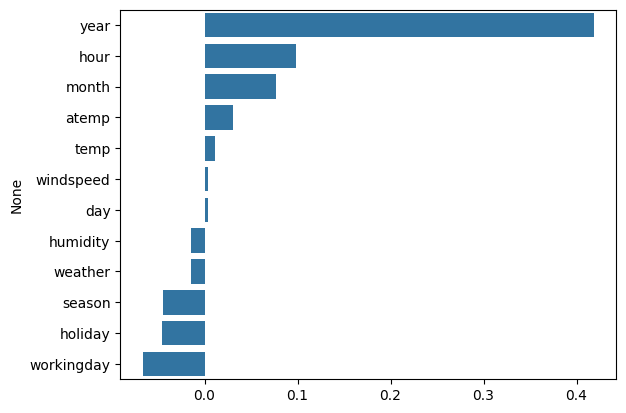

In [20]:
coef = pd.Series(lr_reg.coef_, index=X_features.columns)
coef_sort = coef.sort_values(ascending=False)
sns.barplot(x=coef_sort.values, y=coef_sort.index)


year, hour, month, season, holiday, workingday 피처들의 회귀 계수 영향도가 상대적으로 높다


사이킷런은 카테고리만을 위한 데이터 타입이 없으며, 모두 숫자로 변환해야 한다

In [21]:
# 'year', month’, ‘day’, hour"등의 피처들을 One Hot Encoding
X_features_ohe = pd.get_dummies(X_features, columns=['year', 'month', 'day', 'hour', 'holiday',
                                                     'workingday', 'season', 'weather'])


사이킷런의 선형 회귀 모델인 LinearRegression, Ridge, Lasso 모두 학습해 예측 성능을 확인
- 이를 위해 모델과 학습/테스트 데이터 세트를 입력하면 성능 평가 수치를 반환하는 get_model_
predict() 함수 생성

In [37]:
# 원-핫 인코딩이 적용된 피처 데이터 세트 기반으로 학습/예측 데이터 분할
X_train, X_test, y_train, y_test=train_test_split(X_features_ohe, y_target_log,
                                                  test_size=0.3, random_state=0)
# 모델과 학습/테스트 데이터 세트를 입력하면 성능 평가 수치를 반환
def get_model_predict(model, X_train, X_test, y_train, y_test, is_expm1=False):
  model.fit(X_train, y_train)
  pred=model.predict(X_test)
  if is_expm1:
    y_test=np.expm1(y_test)
    pred=np.expm1(pred)
  print('###', model.__class__.__name__, '###')
  evaluate_regr(y_test, pred)

# end of function get_model_predict

# 모델 별로 평가 수행
lr_reg=LinearRegression()
ridge_reg = Ridge(alpha=10)
lasso_reg = Lasso(alpha=0.01)

for model in [lr_reg, ridge_reg, lasso_reg]:
  get_model_predict(model,X_train, X_test, y_train, y_test,is_expm1=True)

### LinearRegression ###
RMSLE: 0.590, RMSE: 97.688, MAE: 63.382
### Ridge ###
RMSLE: 0.590, RMSE: 98.529, MAE: 63.893
### Lasso ###
RMSLE: 0.635, RMSE: 113.219, MAE: 72.803


원-핫 인코딩을 적용하고 나서 선형 회귀의 예측 성능이 많이 향상되었다

<Axes: ylabel='None'>

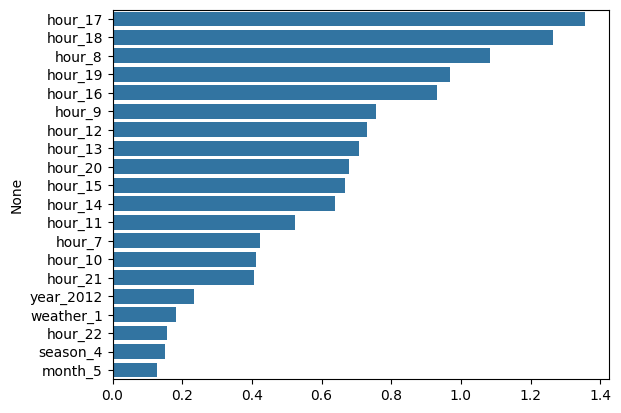

In [26]:
coef = pd.Series(lr_reg.coef_, index=X_features_ohe.columns)
coef_sort = coef.sort_values(ascending=False)[:20]
sns.barplot(x=coef_sort.values , y=coef_sort.index)

원-핫 인코딩 후에는 year_2012, year_2011과 같이 여전히 year 관련 피처들의 회귀 계수 값이 가장 높지만, season_1과 같은 season 관련, weather_1, 2, 3, 4와 같은 weather 관련 속성들의 회귀 계수 값도 상대적으로 커졌다
- 원-핫 인코딩을 통해서 피처들의 영향도가 달라졌고, 모델의 성능도 향상되었다

[ 회귀 트리를 이용해 회귀 예측을 수행 ]

In [27]:
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

# 랜덤 포레스트, GBM, XGBoost, LightGBM model별로 평가 수행
rf_reg = RandomForestRegressor(n_estimators=500)
gbm_reg = GradientBoostingRegressor(n_estimators=500)
xgb_reg = XGBRegressor(n_estimators=500)
lgbm_reg = LGBMRegressor(n_estimators=500)

for model in [rf_reg, gbm_reg, xgb_reg, lgbm_reg]:
  # XGBoost의 경우 DataFrame이 입력될 경우 버전에 따라 오류 발생 가능. ndarray로 변환.
  get_model_predict(model,X_train.values, X_test.values, y_train.values,
                    y_test.values,is_expm1=True)


### RandomForestRegressor ###
RMSLE: 0.355, RMSE: 50.356, MAE: 31.173
### GradientBoostingRegressor ###
RMSLE: 0.330, RMSE: 53.330, MAE: 32.738
### XGBRegressor ###
RMSLE: 0.339, RMSE: 51.475, MAE: 31.357
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002099 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 348
[LightGBM] [Info] Number of data points in the train set: 7620, number of used features: 72
[LightGBM] [Info] Start training from score 4.582043
### LGBMRegressor ###
RMSLE: 0.319, RMSE: 47.215, MAE: 29.029


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


앞의 선형 회귀 모델보다 회귀 예측 성능이 개선됐다

# 회귀 실습 - 캐글 주택 가격: 고급 회귀 기법

# **데이터 사전 처리(Preprocessing)**

이 예제는 데이터 가공을 많이 수행할 예정이므로 원본 csv 파일 기반의 DataFrame은 보관하고 복사해서 데이터를 가공할 예정

In [49]:
import warnings
warnings.filterwarnings('ignore')
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

house_df_org = pd.read_csv('/content/house_price.csv')
house_df = house_df_org.copy()
house_df.head(3)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500


In [30]:
print('데이터 세트의 Shape：', house_df.shape)
print('\n전체 피처의 type \n', house_df.dtypes.value_counts())
isnull_series = house_df.isnull().sum()
print('\nNull 칼럼과 그 건수:\n', isnull_series[isnull_series > 0].sort_values(ascending=False))

데이터 세트의 Shape： (1460, 81)

전체 피처의 type 
 object     43
int64      35
float64     3
Name: count, dtype: int64

Null 칼럼과 그 건수:
 PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64


데이터 세트는 1460개의 레코드와 81개의 피처로 구성돼 있으며, 피처의 타입은 숫자형은 물론 문자형도 많이 있다
- Target을 제외한 80개의 피처 중 43개가 문자형이며 나머지가 숫자형
-  데이터 양에 비해 Null 값이 많은 피처도 존재
  - 전체 1480개 데이터 중 PoolQC, MiscFeature, Alley, Fence는 1000개가 넘는 데이터가 Null
    - Null 값이 너무 많은 피처는 드롭

[ 회귀 모델을 적용하기 전에 타깃 값의 분포도가 정규 분포인지 확인 ]

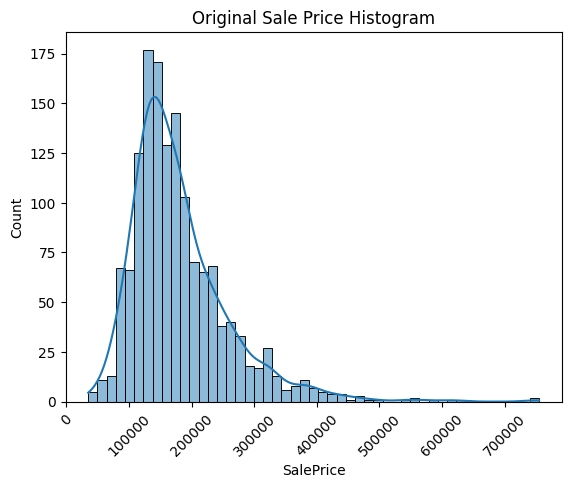

In [34]:
plt.title('Original Sale Price Histogram')
plt.xticks(rotation=45)
sns.histplot(house_df['SalePrice'], kde=True)
plt.show()

데이터 값의 분포가 중심에서 왼쪽으로 치우친 형태로, 정규 분포에서 벗어나 있다

정규 분포가 아닌 결괏값을 정규 분포 형태로 변환하기 위해 로그 변환(Log Transformation)을 적용
- 먼저 넘파이의 log1p( )를 이용해 로그 변환한 결괏값을 기반으로 학습한 뒤, 예측 시에는 다시 결괏값을 expm1()으로 추후에 환원

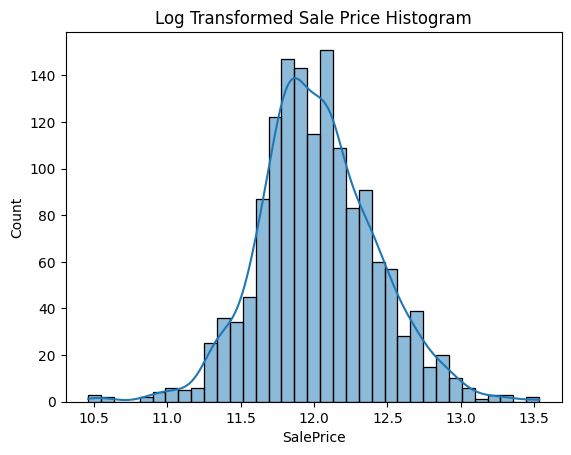

In [35]:
plt.title('Log Transformed Sale Price Histogram')
log_SalePrice = np.log1p(house_df['SalePrice'])
sns.histplot(log_SalePrice, kde=True)
plt.show()

SalePrice를 로그 변환해 정규 분포 형태로 결괏값이 분포함을 확인 가능

Next>>
- SalePrice를 로그 변환한 뒤 DataFrame에 반영
- Null 값이 많은 피처인 PoolQC, MiscFeature, Alley, Fence, FireplaceQu는 삭제
- Id도 단순 식별자이므로 삭제
-  LotFrontage는 Null이 259개로 비교적 많으나 평균값으로 대체
- 나머지 Null 피처는 Null 값이 많지 않으므로 숫자형의 경우 평균값으로 대체

In [50]:
# SalePrice 로그 변환
original_SalePrice = house_df['SalePrice']
house_df['SalePrice'] = np.log1p(house_df['SalePrice'])

# Null이 너무 많은 칼럼과 불필요한 칼럼 삭제
house_df.drop(['Id', 'PoolQC', 'MiscFeature', 'Alley', 'Fence', 'FireplaceQu'],axis=1,
              inplace=True)

# 드롭하지 않는 숫자형 Null 칼럼은 평균값으로 대체 (numeric_only=True 옵션 추가)
numerical_cols = house_df.select_dtypes(include=np.number).columns
house_df[numerical_cols] = house_df[numerical_cols].fillna(house_df[numerical_cols].mean())

# Null 값이 있는 피처명과 타입을 추출
null_column_count = house_df.isnull().sum()[house_df.isnull().sum() > 0]
print('## Null 피처의 Type ：\n',  house_df.dtypes[null_column_count.index])

## Null 피처의 Type ：
 MasVnrType      object
BsmtQual        object
BsmtCond        object
BsmtExposure    object
BsmtFinType1    object
BsmtFinType2    object
Electrical      object
GarageType      object
GarageFinish    object
GarageQual      object
GarageCond      object
dtype: object


Null 값을 가진 피처는 모두 문자형만 존재
- 문자형 피처는 모두 원-핫 인코딩으로 변환
  - 판다스의 get_dummies()를 이용

- 가령 BsmtQual 칼럼값이 'Gd', 'Ex', 'FA'’ 외에 Null 값이 존재한다면 Null은 [0, 0, 0, 0]
과 같이 BstmtQual의 4개의 종류로 만들어진 인코딩 값을 모두 0으로 하여 원-핫 인코딩 변환된다
  - 4개의 값 중에 반드시 1 개는 1 이 되는 일반적인 원-핫 인코딩과 다르게 변환된다
  - 원-핫 인코딩을 적용하면 당연히 칼럼이 증가한다

In [51]:
print('get_dummies() 수행 전 데이터 Shape：', house_df.shape)
house_df_ohe = pd.get_dummies(house_df)
print('get_dummies() 수행 후 데이터 Shape：', house_df_ohe.shape)
null_column_count = house_df_ohe.isnull().sum()[house_df_ohe.isnull().sum() > 0]
print('## Null 피처의 Type :\n', house_df_ohe.dtypes[null_column_count.index])

get_dummies() 수행 전 데이터 Shape： (1460, 75)
get_dummies() 수행 후 데이터 Shape： (1460, 270)
## Null 피처의 Type :
 Series([], dtype: object)


# **선형 회귀 모델 학습/예측/평가**

In [53]:
def get_rmse(model):
  pred=model.predict(X_test)
  mse=mean_squared_error(y_test, pred)
  rmse=np.sqrt(mse)
  print(model.__class__.__name__, '로그 변환된 RMSE:', np.round(rmse, 3))
  return rmse

def get_rmses(models):
  rmses=[]
  for model in models:
    rmse=get_rmse(model)
    rmses.append(rmse)
  return rmses


In [54]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

y_target = house_df_ohe['SalePrice']
X_features = house_df_ohe.drop('SalePrice', axis=1, inplace=False)
X_train, X_test, y_train, y_test = train_test_split(X_features, y_target, test_size=0.2,
                                                    random_state=156)

# LinearRegression, Ridge, Lasso 학습, 예측, 평가
lr_reg = LinearRegression()
lr_reg.fit(X_train, y_train)
ridge_reg = Ridge()
ridge_reg.fit(X_train, y_train)
lasso_reg = Lasso()
lasso_reg.fit(X_train, y_train)

models = [lr_reg, ridge_reg, lasso_reg]
get_rmses(models)

LinearRegression 로그 변환된 RMSE: 0.132
Ridge 로그 변환된 RMSE: 0.127
Lasso 로그 변환된 RMSE: 0.176


[np.float64(0.13183184688250701),
 np.float64(0.1274058283626616),
 np.float64(0.17628250556471403)]

라쏘 회귀의 경우 회귀 성능이 타 회귀 방식보다 많이 떨어지는 결과가 나왔다
- 라쏘의 경우 최적 하이퍼 파라미터 튜닝이 필요해 보인다

[ 먼저 피처별 회귀 계수를 시각화해서 모델별로 어떠한 피처의 회귀 계수로 구성되는지 확인 ]
- 피처가 많으므로 회귀 계수 값의 상위 10개, 하위 10개의 피처명과 그 회귀 계수 값을 가지는 판다스 Series 객체를 반환하는 함수 만들기

In [57]:
def get_top_bottom_coef(model, rr=10):
  # coef_ 속성을 기반으로 Series 객체를 생성. index는 칼럼명.
  coef = pd.Series(model.coef_, index=X_features.columns)

  # + 상위 10개, - 하위 10개의 회귀 계수를 추출해 반환.
  coef_high = coef.sort_values(ascending=False).head(rr)
  coef_low = coef.sort_values(ascending=False).tail(rr)
  return coef_high, coef_low

생성한 get_top_bottom_coef(model, n=10 ) 함수를 이용해 모델별 회귀 계수를 시각화
- 시각화 함수로 visualize_coefficient(models)를 생성
  - 해당 함수는 list 객체로 모델을 입
력받아 모델별로 회귀 계수 상위 10개, 하위 10개를 추출해 가로 막대 그래프 형태로 출력

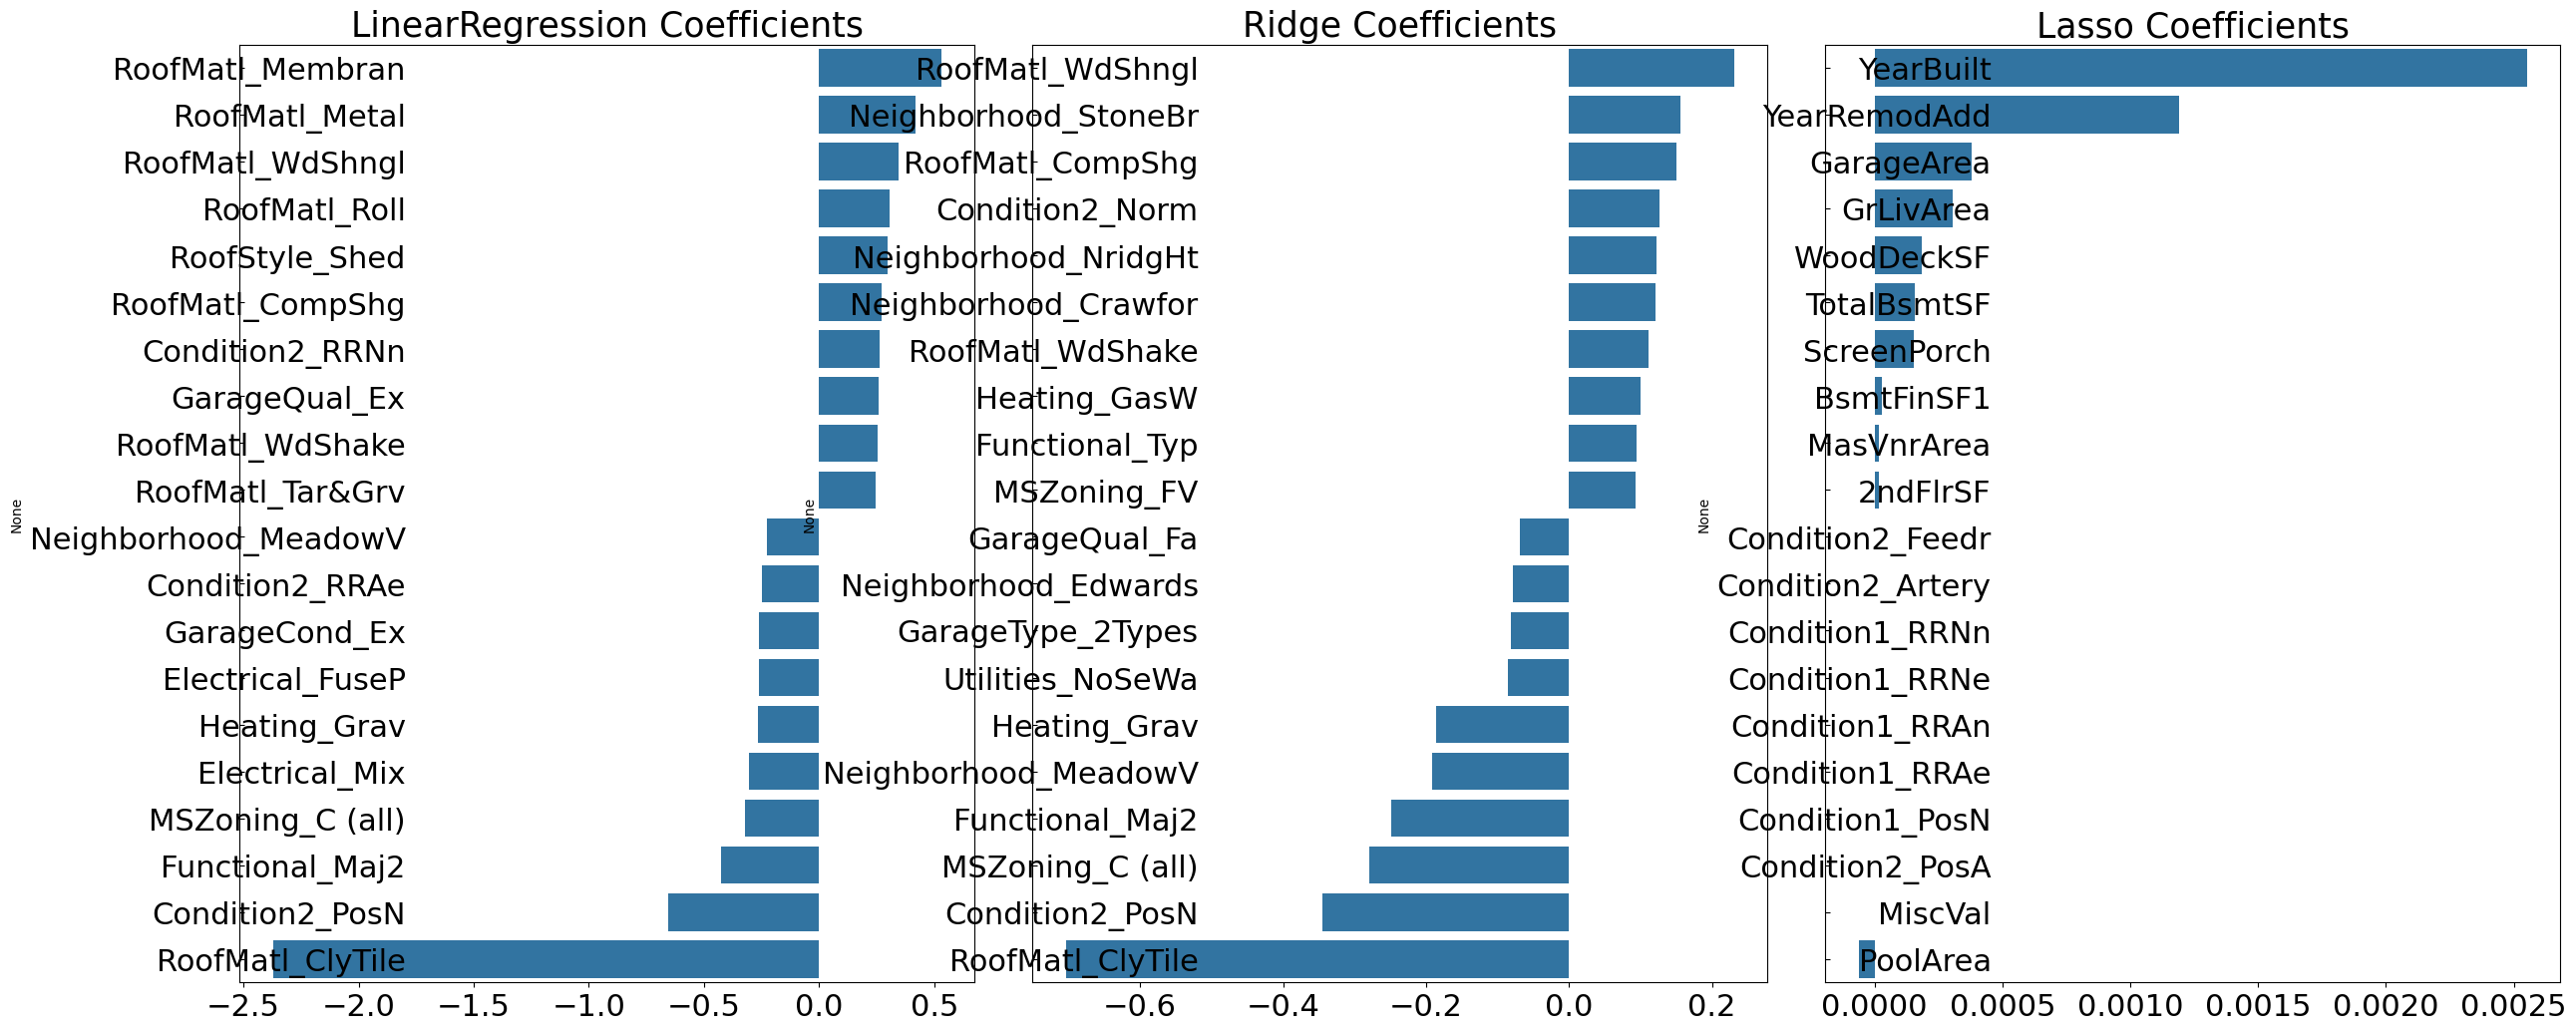

In [58]:
def visualize_coefficient(models):
  # 3개 회귀 모델의 시각화를 위해 3개의 칼럼을 가지는 subplot 생성
  fig, axs = plt.subplots(figsize=(24, 10), nrows=1, ncols=3)
  fig.tight_layout()

  # 입력 인자로 받은 list 객체인 models에서 차례로 model을 추출해 회귀 계수 시각화.
  for i_num, model in enumerate(models):

    # 상위 10개, 하위 10개 회귀 계수를 구하고, 이를 판다스 concat으로 결합
    coef_high, coef_low = get_top_bottom_coef(model)
    coef_concat = pd.concat( [coef_high, coef_low] )

    # ax subplot에 barplot으로 표현. 한 화면에 표현하기 위해 tick label 위치와 font 크기 조정.
    axs[i_num].set_title(model.__class__.__name__+' Coefficients', size=25)
    axs[i_num].tick_params(axis="y", direction="in", pad=-120)
    for label in (axs[i_num].get_xticklabels() + axs[i_num].get_yticklabels()):
      label.set_fontsize(22)
    sns.barplot(x=coef_concat.values, y=coef_concat.index, ax=axs[i_num])

# 앞 예제에서 학습한 lr_reg, ridge_reg, lasso_reg 모델의 회귀 계수 시각화.
models = [lr_reg, ridge_reg, lasso_reg]
visualize_coefficient(models)

모델별 회귀 계수를 보면 OLS 기반의 LinearRegression과 Ridge의 경우는 회귀 계수가 유사한 형태로 분포돼 있다
- 하지만 라쏘(Lasso)는 전체적으로 회귀 계수 값이 매우 작고, 그중에 YearBuilt가 가장 크고 다른 피처의 회귀 계수는 너무 작다
  - 라쏘의 경우 다른 두 개의 모델과 다른 회귀 계수 형태를 보이고 있다


[ 이번에는 학습과 테스트 데이터 세트를 train_test_split()으로 분할하지 않고 전체 데이터 세트인 X_features와 y_target을 5개의 교차 검증 폴드 세트로 분할해 평균 RMSE를 측정 ]
- cross_val_score()를 이용

In [60]:
from sklearn.model_selection import cross_val_score

def get_avg_rmse_cv(models):
  for model in models:
    # 분할하지 않고 전체 데이터로 cross_val_score( ) 수행. 모델별 CV RMSE값과 평균 RMSE 출력
    rmse_list = np.sqrt(-cross_val_score(model, X_features, y_target,
                                         scoring="neg_mean_squared_error", cv = 5))
    rmse_avg = np.mean(rmse_list)
    print('\n{0} CV RMSE 값 리스트: {1}'.format(model.__class__.__name__, np.round(rmse_list, 3)))
    print('{0} CV 평균 RMSE 값: {1}'.format(model.__class__.__name__, np.round(rmse_avg, 3)))

# 앞 예제에서 학습한 ridge_reg, lasso_reg 모델의 CV RMSE값 출력
models = [ridge_reg, lasso_reg]
get_avg_rmse_cv(models)


Ridge CV RMSE 값 리스트: [0.117 0.154 0.142 0.117 0.189]
Ridge CV 평균 RMSE 값: 0.144

Lasso CV RMSE 값 리스트: [0.161 0.204 0.177 0.181 0.265]
Lasso CV 평균 RMSE 값: 0.198


5개의 폴드 세트로 학습한 후 평가해도 여전히 라쏘의 경우 릿지 모델보다 성능이 떨어진다

[ 릿지와 라쏘 모델에 대해서 alpha 하이퍼 파라미터를 변화시키면서 최적 값을 도출 ]

In [62]:
from sklearn.model_selection import GridSearchCV

def print_best_params(model, params):
  grid_model = GridSearchCV(model, param_grid=params,
                            scoring='neg_mean_squared_error', cv=5)
  grid_model.fit(X_features, y_target)
  rmse = np.sqrt(-1* grid_model.best_score_)
  print('{0} 5 CV 시 최적 평균 RMSE 값:{1}, 최적 alpha：{2}'.format(model.__class__.__name__,
                                                           np.round(rmse, 4), grid_model.best_params_))

ridge_params = { 'alpha':[0.05, 0.1, 1, 5, 8, 10, 12, 15, 20] }
lasso_params = { 'alpha':[0.001, 0.005, 0.008, 0.05, 0.03, 0.1, 0.5, 1, 5, 10] }
print_best_params(ridge_reg, ridge_params)
print_best_params(lasso_reg, lasso_params)

Ridge 5 CV 시 최적 평균 RMSE 값:0.1418, 최적 alpha：{'alpha': 12}
Lasso 5 CV 시 최적 평균 RMSE 값:0.142, 최적 alpha：{'alpha': 0.001}


- 릿지 모델의 경우 alpha가 12에서 최적 평균 RMSE가 0.1418, 라쏘 모델의 경우 alpha가 0.0이에서 최적 평균 RMSE가 0.142
- 라쏘 모델의 경우, alpha 값 최적화 이후 예측 성능이 많이 좋아졌다

LinearRegression 로그 변환된 RMSE: 0.132
Ridge 로그 변환된 RMSE: 0.124
Lasso 로그 변환된 RMSE: 0.12


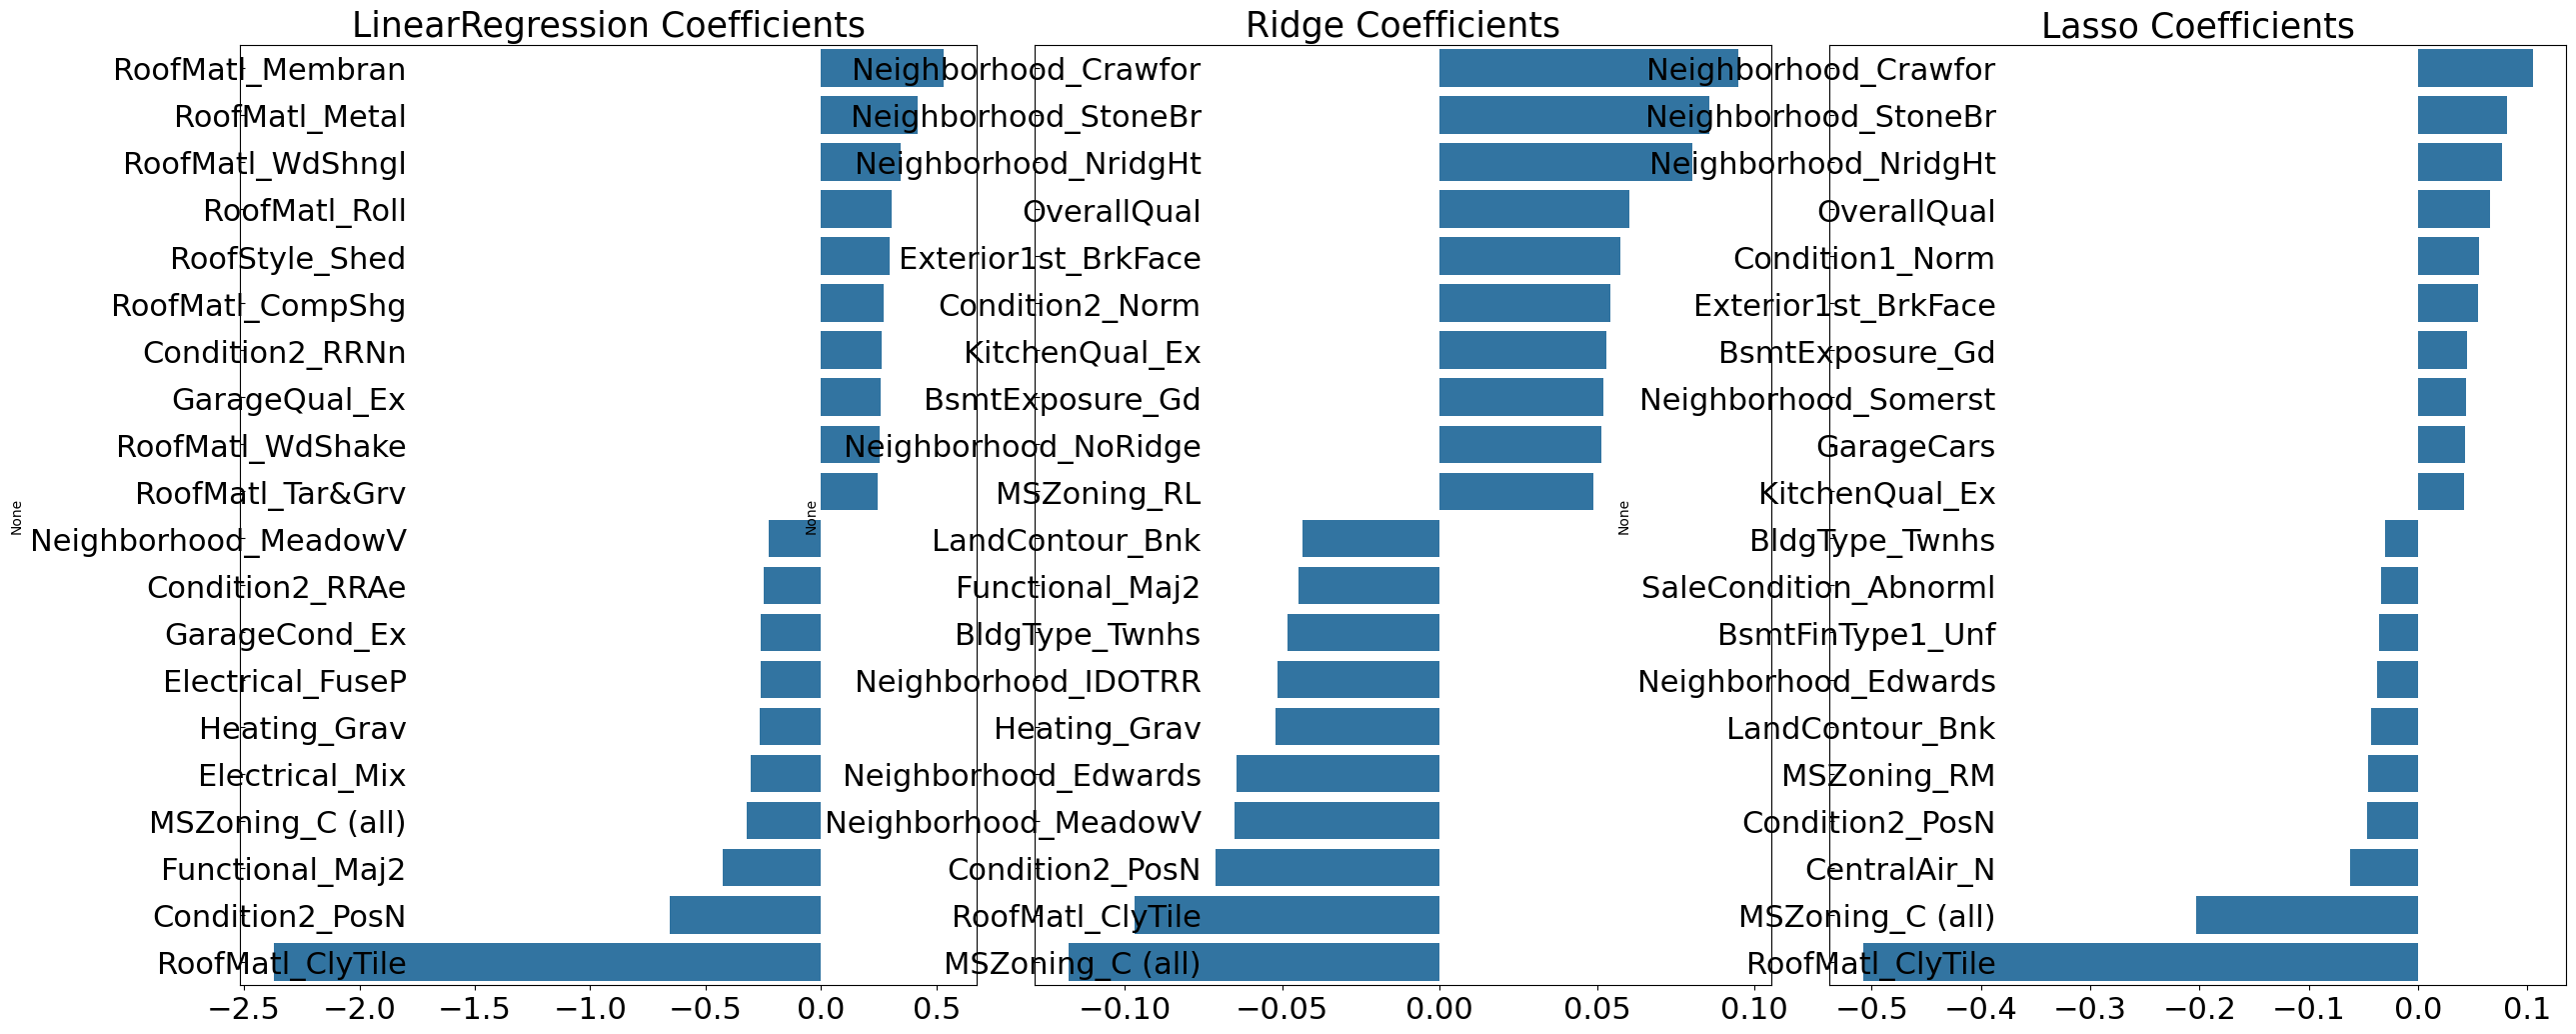

In [63]:
# 앞의 최적화 alpha 값으로 학습 데이터로 학습, 테스트 데이터로 예측 및 평가 수행.
lr_reg = LinearRegression()
lr_reg.fit(X_train, y_train)
ridge_reg = Ridge(alpha=12)
ridge_reg.fit(X_train, y_train)
lasso_reg = Lasso(alpha=0.001)
lasso_reg.fit(X_train, y_train)

# 모든 모델의 RMSE 출력
models = [lr_reg, ridge_reg, lasso_reg]
get_rmses(models)

# 모든 모델의 회귀 계수 시각화
models = [lr_reg, ridge_reg, lasso_reg]
visualize_coefficient(models)


- alpha 값 최적화 후 테스트 데이터 세트의 예측 성능이 더 좋아졌다
- 모델 별 회귀계수도 많이 달라졌다
  - 기존, 라쏘 모델의 회귀 계수가 나머지 두 개 모델과 많은 차이가 있었으나 이번에는 릿지와 라쏘 모델에서 비슷한 피처의 회귀 계수가 높다
  - 다만 라쏘 모델의 경우엔 릿지에 비해 동일한 피처라도 회귀 계수의 값이 상당히 작다

데이터 세트를 추가적으로 가공해서 모델 튜닝을 좀 더 진행
- 1. 피처 데이터 세트의 데이터 분포도
- 2. 이상치(Outlier) 데이터 처리

[ 1. 모든 숫자형 피처의 데이터 분포도를 확인해 분포도가 어느 정도로 왜곡됐는지 알아보기 ]
- 사이파이 stats 모듈의 skew() 함수를 이용해 칼럼의 데이터 세트의 왜곡된 정도를 쉽게 추출
  - 일반적으로 skew( ) 함수의 반환 값이 1 이상인 경우를 왜곡 정도가 높다고 판단하지만 상황에 따라 편차 존재
  - 여기서는 1 이상의 값을 반환하는 피처만 추출해 왜곡 정도를 완화하기 위해 로그 변환을 적용


다음 예제 코드에서는 숫자형 피처의 칼럼 index 객체를 추출해 구한 숫자형 칼럼 데이터 세트의 apply lambda 식 skew()를 호출해 숫자형 피처의 왜곡 정도 구하기
- 주의할 점 = skew()를 적용하는 숫자형 피처에서 원-핫 인코딩된 카테고리 숫자형 피처는 제외
  - 카테고리 피처는 코드성 피처이므로 인코딩 시 당연히 왜곡될 가능성이 높다
  - 따라서 skew() 함수를 적용하는 DataFrame은 원一핫 인코딩 이 적용된 house_df_ohe가 아니라 원-핫 인코딩이 적용되지 않은 house_df이어야 한다

In [64]:
from scipy.stats import skew

# object가 아닌 숫자형 피처의 칼럼 index 객체 추출
features_index=house_df.dtypes[house_df.dtypes!='object'].index
# house_df에 칼럼 index를 []로 입력하면 해당하는 칼럼 데이터 세트 반환, apply lambda로 skew() 호출
skew_features=house_df[features_index].apply(lambda x :skew(x))
# skew(왜곡) 정도가 1 이상인 칼럼만 추출
skew_features_top=skew_features[skew_features>1]
print(skew_features_top.sort_values(ascending=False))

MiscVal          24.451640
PoolArea         14.813135
LotArea          12.195142
3SsnPorch        10.293752
LowQualFinSF      9.002080
KitchenAbvGr      4.483784
BsmtFinSF2        4.250888
ScreenPorch       4.117977
BsmtHalfBath      4.099186
EnclosedPorch     3.086696
MasVnrArea        2.673661
LotFrontage       2.382499
OpenPorchSF       2.361912
BsmtFinSF1        1.683771
WoodDeckSF        1.539792
TotalBsmtSF       1.522688
MSSubClass        1.406210
1stFlrSF          1.375342
GrLivArea         1.365156
dtype: float64


이제 추출된 왜곡 정도가 높은 피처를 로그 변환

In [66]:
house_df[skew_features_top.index] = np.log1p(house_df[skew_features_top.index])

In [68]:
# 왜곡 정도가 높은 피처를 로그 변환했으므로 다시 원-핫 인코딩을 적용하고 피처/타깃 데이터 세트 생성
house_df_ohe = pd.get_dummies(house_df)
y_target = house_df_ohe['SalePrice']
X_features = house_df_ohe.drop('SalePrice', axis=1, inplace=False)
X_train, X_test, y_train, y_test = train_test_split(X_features, y_target, test_size=0.2,
                                                    random_state=156)

# 피처를 로그 변환한 후 다시 최적 하이퍼 파라미터와 RMSE 출력
ridge_params = {'alpha':[0.05, 0.1, 1, 5, 8, 10, 12, 15, 20]}
lasso_params = {'alpha':[0.001, 0.005, 0.008, 0.05, 0.03, 0.1, 0.5, 1, 5, 10]}
print_best_params(ridge_reg, ridge_params)
print_best_params(lasso_reg, lasso_params)

Ridge 5 CV 시 최적 평균 RMSE 값:0.1275, 최적 alpha：{'alpha': 10}
Lasso 5 CV 시 최적 평균 RMSE 값:0.1252, 최적 alpha：{'alpha': 0.001}


릿지 모델의 경우 최적 alpha값이 12에서 10으로 변경됐고, 두 모델 모두 피처의 로그 변환 이전과 비교해 릿지의 경우 0.1418에서 0.1275로, 라쏘의 경우 0.142에서 0.1252로, 5 폴드 교차 검증의 평균 RMSE값이 향상

LinearRegression 로그 변환된 RMSE: 0.128
Ridge 로그 변환된 RMSE: 0.122
Lasso 로그 변환된 RMSE: 0.119


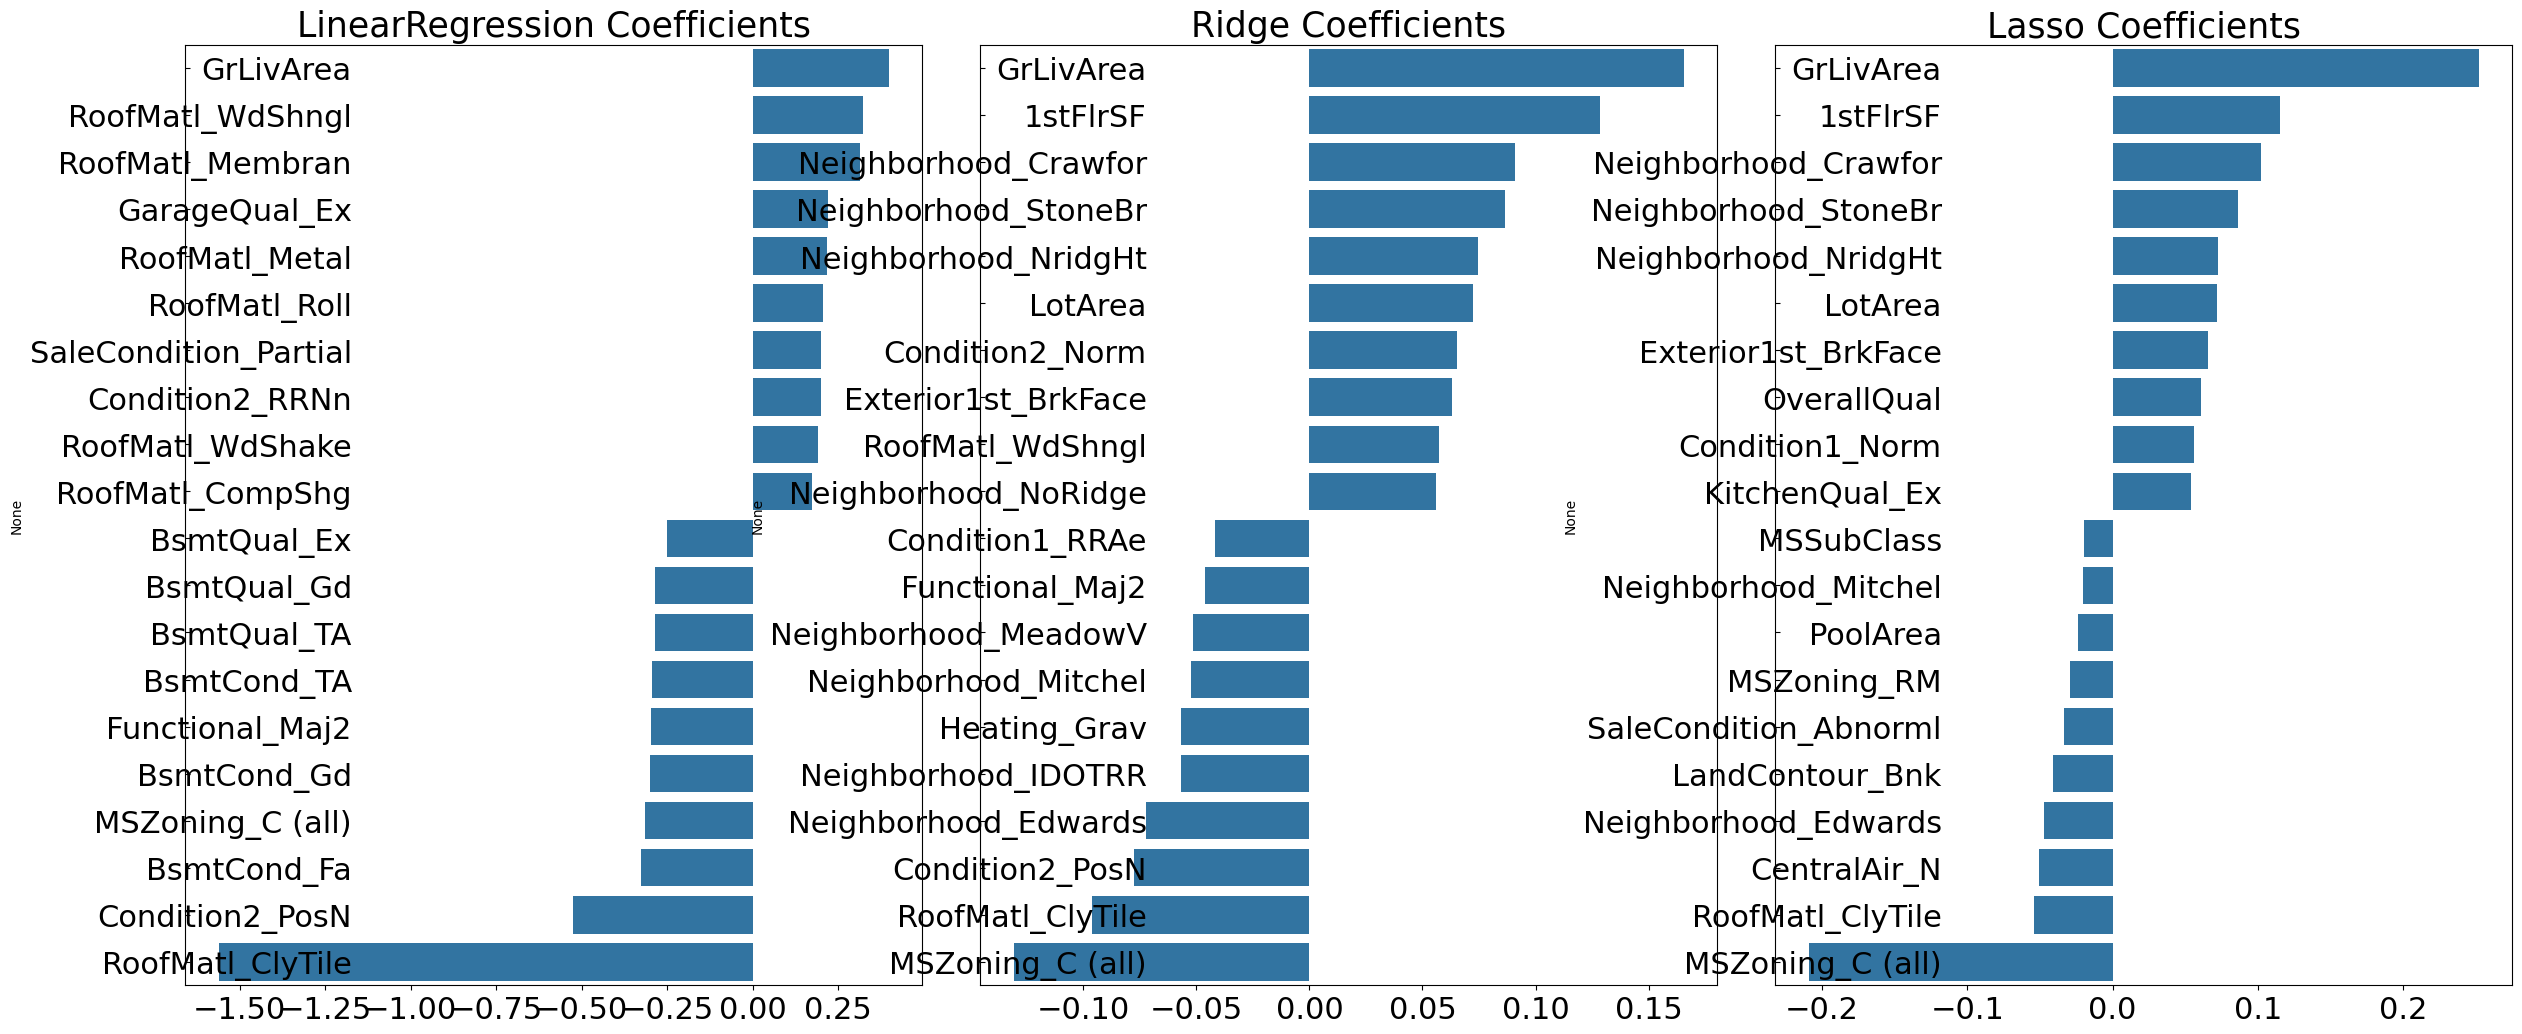

In [70]:
# 로그 변환된 데이터로 모델 재학습 (alpha는 위에서 찾은 최적값)
lr_reg = LinearRegression()
lr_reg.fit(X_train, y_train)
ridge_reg = Ridge(alpha=10)
ridge_reg.fit(X_train, y_train)
lasso_reg = Lasso(alpha=0.001)
lasso_reg.fit(X_train, y_train)

# 모든 모델의 RMSE 출력
models = [lr_reg, ridge_reg, lasso_reg]
get_rmses(models)

# 모든 모델의 회귀 계수 시각화
visualize_coefficient(models)

[ 2. 이상치 데이터 분석 ]
- 회귀 계수가 높은 피처(예측에 많은 영향을 미치는 중요 피처)의 이상치 데이터의 처리가 중요

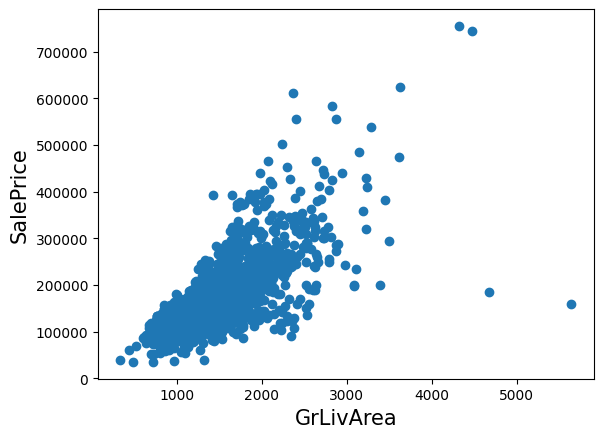

In [71]:
plt.scatter(x = house_df_org['GrLivArea'], y = house_df_org['SalePrice'])
plt.ylabel('SalePrice', fontsize=15)
plt.xlabel('GrLivArea', fontsize=15)
plt.show()

일반적으로 주거 공간이 큰 집일 수록 가격이 비싸기에 GrLivArea 피처는 ScalePrice와 양의 상관도가 매우 높음을 알 수 있다
- GrLivArea가 4000평방피트 이상임에도 가격이 500,000달러 이하인 데이터는 모두 이상치로 간주하고 삭제

In [72]:
# GrLivArea와 SalePrice 모두 로그 변환됐으므로 이를 반영한 조건 생성
cond1 = house_df_ohe['GrLivArea'] > np.log1p(4000)
cond2 = house_df_ohe['SalePrice'] < np.log1p(500000)
outlier_index = house_df_ohe[cond1 & cond2].index

print('이상치 레코드 index:', outlier_index.values)
print('이상치 삭제 전 house_df_ohe shape：', house_df_ohe.shape)

# DataFrame의 인덱스를 이용해 이상치 레코드 삭제.
house_df_ohe.drop(outlier_index, axis=0, inplace=True)
print('이상치 삭제 후 house_df_ohe shape：', house_df_ohe.shape)


이상치 레코드 index: [ 523 1298]
이상치 삭제 전 house_df_ohe shape： (1460, 270)
이상치 삭제 후 house_df_ohe shape： (1458, 270)


레코드 인덱스 523, 1298이 대상이며 두 개의 데이터를 삭제해 전체 레코드는 1460개에서 1458개로
줄었다

In [75]:
# print_best_params( ) 함수를 이용해 릿지와 라쏘 모델의 최적화를 수행하고 결과를 출력
y_target=house_df_ohe['SalePrice']
X_features=house_df_ohe.drop('SalePrice', axis=1, inplace=False)
X_train, X_test, y_train, y_test=train_test_split(X_features, y_target, test_size=0.2,
                                                  random_state=156)
ridge_params={'alpha':[0.05,0.1,1,5,8,10,12,15,20]}
lasso_params={'alpha':[0.001,0.005,0.008,0.05,0.03,0.1,0.5,1,5,10]}
print_best_params(ridge_reg, ridge_params)
print_best_params(lasso_reg, lasso_params)

Ridge 5 CV 시 최적 평균 RMSE 값:0.1125, 최적 alpha：{'alpha': 8}
Lasso 5 CV 시 최적 평균 RMSE 값:0.1122, 최적 alpha：{'alpha': 0.001}


단 두 개의 이상치 데이터만 제거했는데, 예측 수치가 매우 크게 향상됐다
- 릿지 모델의 경우 최적 alpha 값은 12에서 8로 변했고, 평균 RMSE가 0.1275에서 0.1125로 개선됐다
-  라쏘 모델의 경우는 평균 RMSE가 0.1252에서 0.1122로 개선됐습니다. 라쏘 모델의 경우 RMSE가 약 0.128에서 약 0.114로 매우 낮아졌다

--> GrLivArea 속성이 회귀 모델에서 차지하는 영향도가 크기에 이 이상치를 개선하는 것이 성능
개선에 큰 의미를 가졌다

LinearRegression 로그 변환된 RMSE: 0.129
Ridge 로그 변환된 RMSE: 0.103
Lasso 로그 변환된 RMSE: 0.1


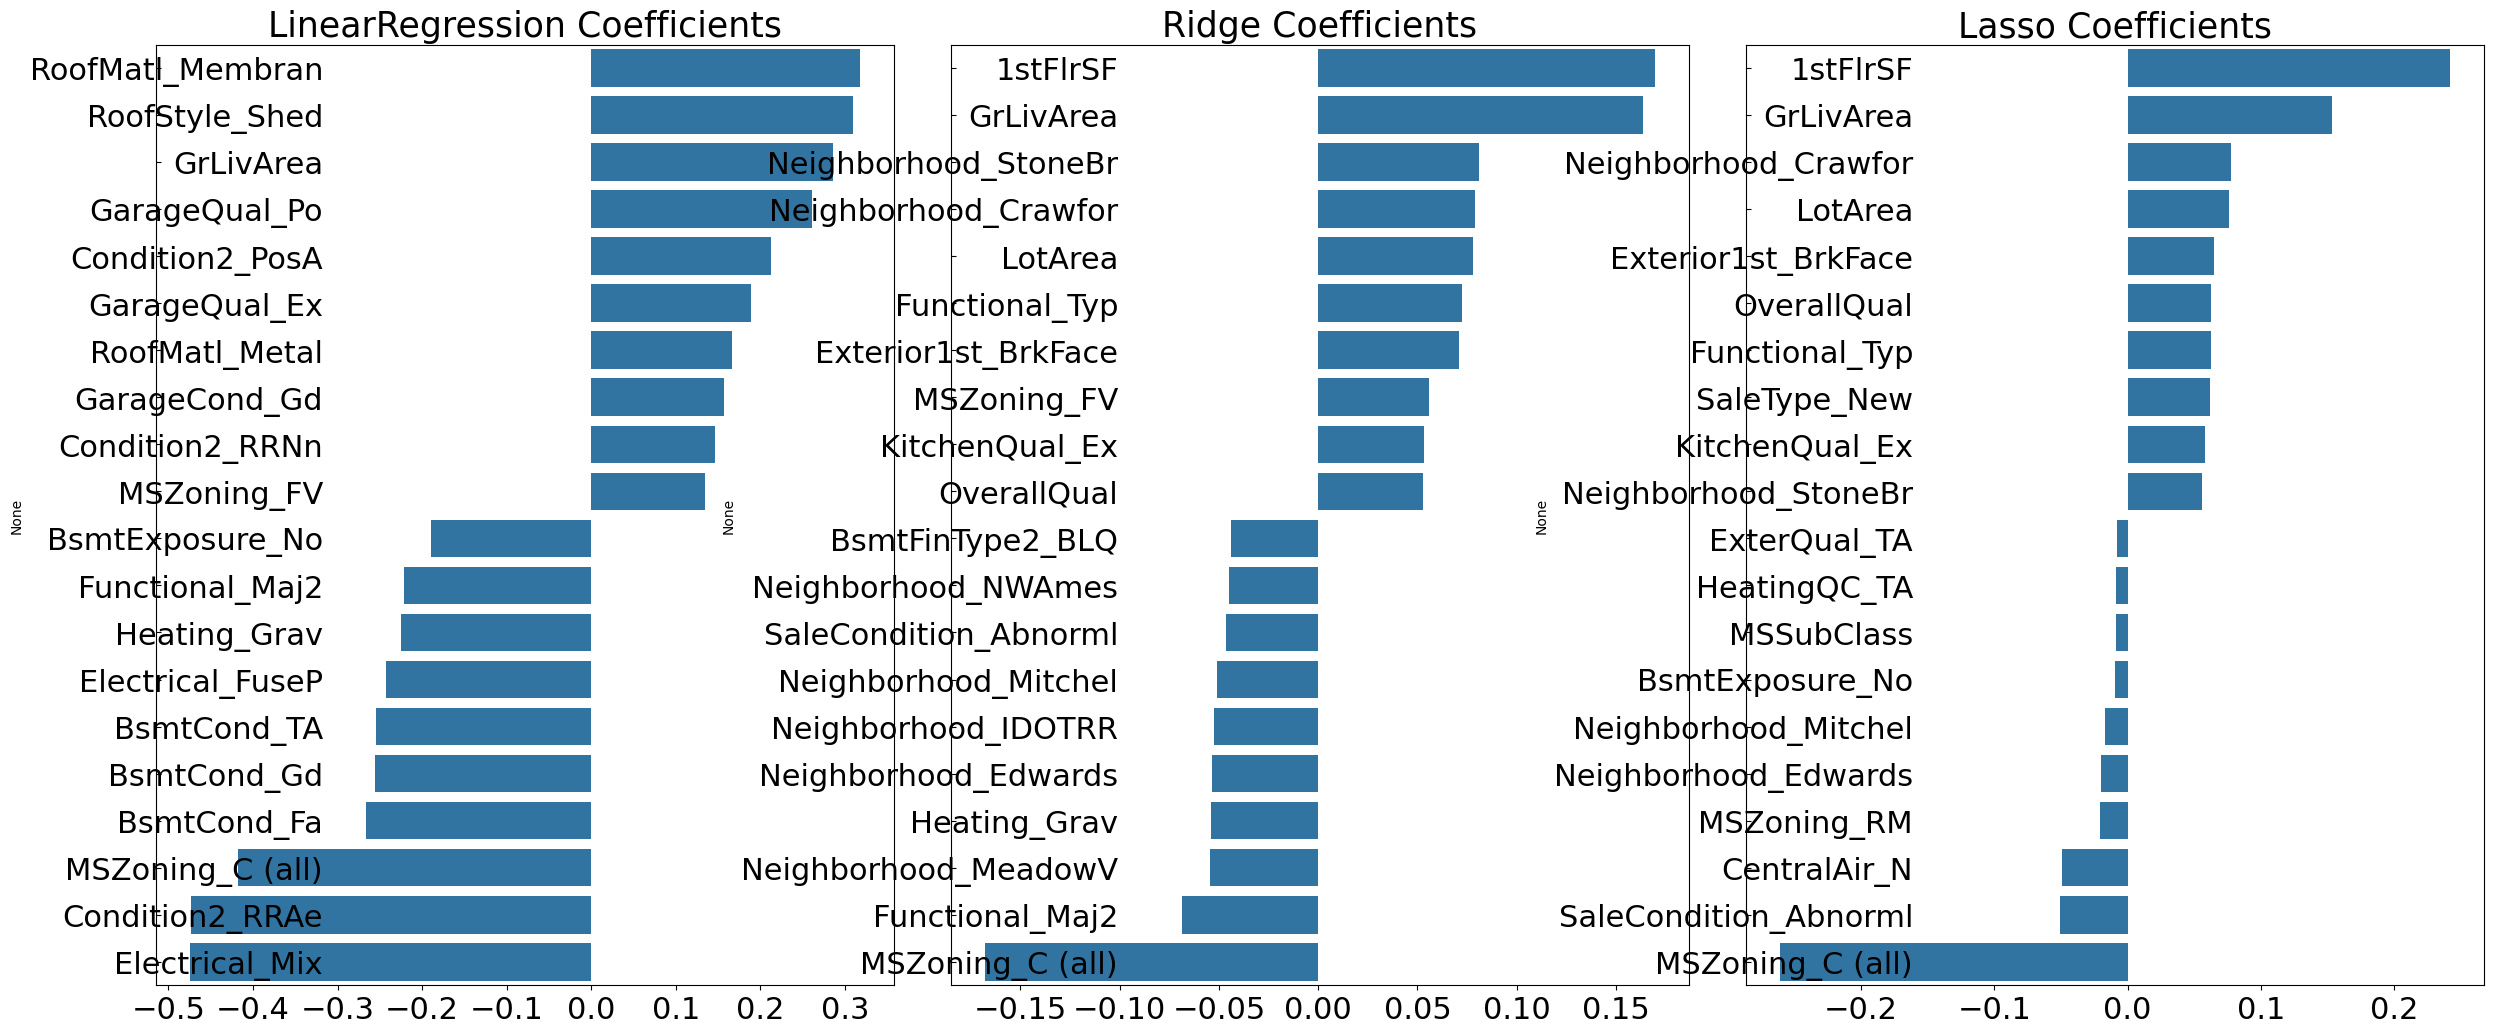

In [76]:
# 이상치가 제거된 house_df_ohe 기반으로 피처/타깃 및 학습/테스트 데이터 재생성
y_target = house_df_ohe['SalePrice']
X_features = house_df_ohe.drop('SalePrice', axis=1, inplace=False)
X_train, X_test, y_train, y_test = train_test_split(X_features, y_target,
                                                    test_size=0.2, random_state=156)

# 이상치 제거 후 찾은 최적 alpha로 모델 재학습
lr_reg = LinearRegression()
lr_reg.fit(X_train, y_train)
ridge_reg = Ridge(alpha=8)
ridge_reg.fit(X_train, y_train)
lasso_reg = Lasso(alpha=0.001)
lasso_reg.fit(X_train, y_train)

# 모든 모델의 RMSE 출력
models = [lr_reg, ridge_reg, lasso_reg]
get_rmses(models)

# 모든 모델의 회귀 계수 시각화
visualize_coefficient(models)

## **회귀 트리 모델 학습/예측/평가**

XGBoost, LightGBM 모두 수행 시간이 오래
걸릴 수 있는 관계로 다음과 같은 하이퍼 파라미터 설정을 미리 적용한 상태로 5 폴드 세트에 대한 평
균 RMSE 값을 구하기

In [78]:
from xgboost import XGBRegressor
xgb_params = {'n_estimators':[1000]}
xgb_reg = XGBRegressor(n_estimators=1000, learning_rate=0.05, colsample_bytree=0.5, subsample=0.8)
print_best_params(xgb_reg, xgb_params)


XGBRegressor 5 CV 시 최적 평균 RMSE 값:0.1205, 최적 alpha：{'n_estimators': 1000}


In [79]:
from lightgbm import LGBMRegressor
lgbm_params = {'n_estimators':[1000]}
lgbm_reg = LGBMRegressor(n_estimators=1000, learning_rate=0.05, num_leaves=4,
                         subsample=0.6, colsample_bytree=0.4, reg_lambda=10, n_jobs=-1)
print_best_params(lgbm_reg, lgbm_params)



[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.024121 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 3155
[LightGBM] [Info] Number of data points in the train set: 1166, number of used features: 171
[LightGBM] [Info] Start training from score 12.021352
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.136408 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 3167
[LightGBM] [Info] Number of data points in the train set: 1166, number of used features: 168
[LightGBM] [Info] Start training from score 12.023516
[LightGBM] [Warning] Found

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001208 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 3434
[LightGBM] [Info] Number of data points in the train set: 1458, number of used features: 177
[LightGBM] [Info] Start training from score 12.024015


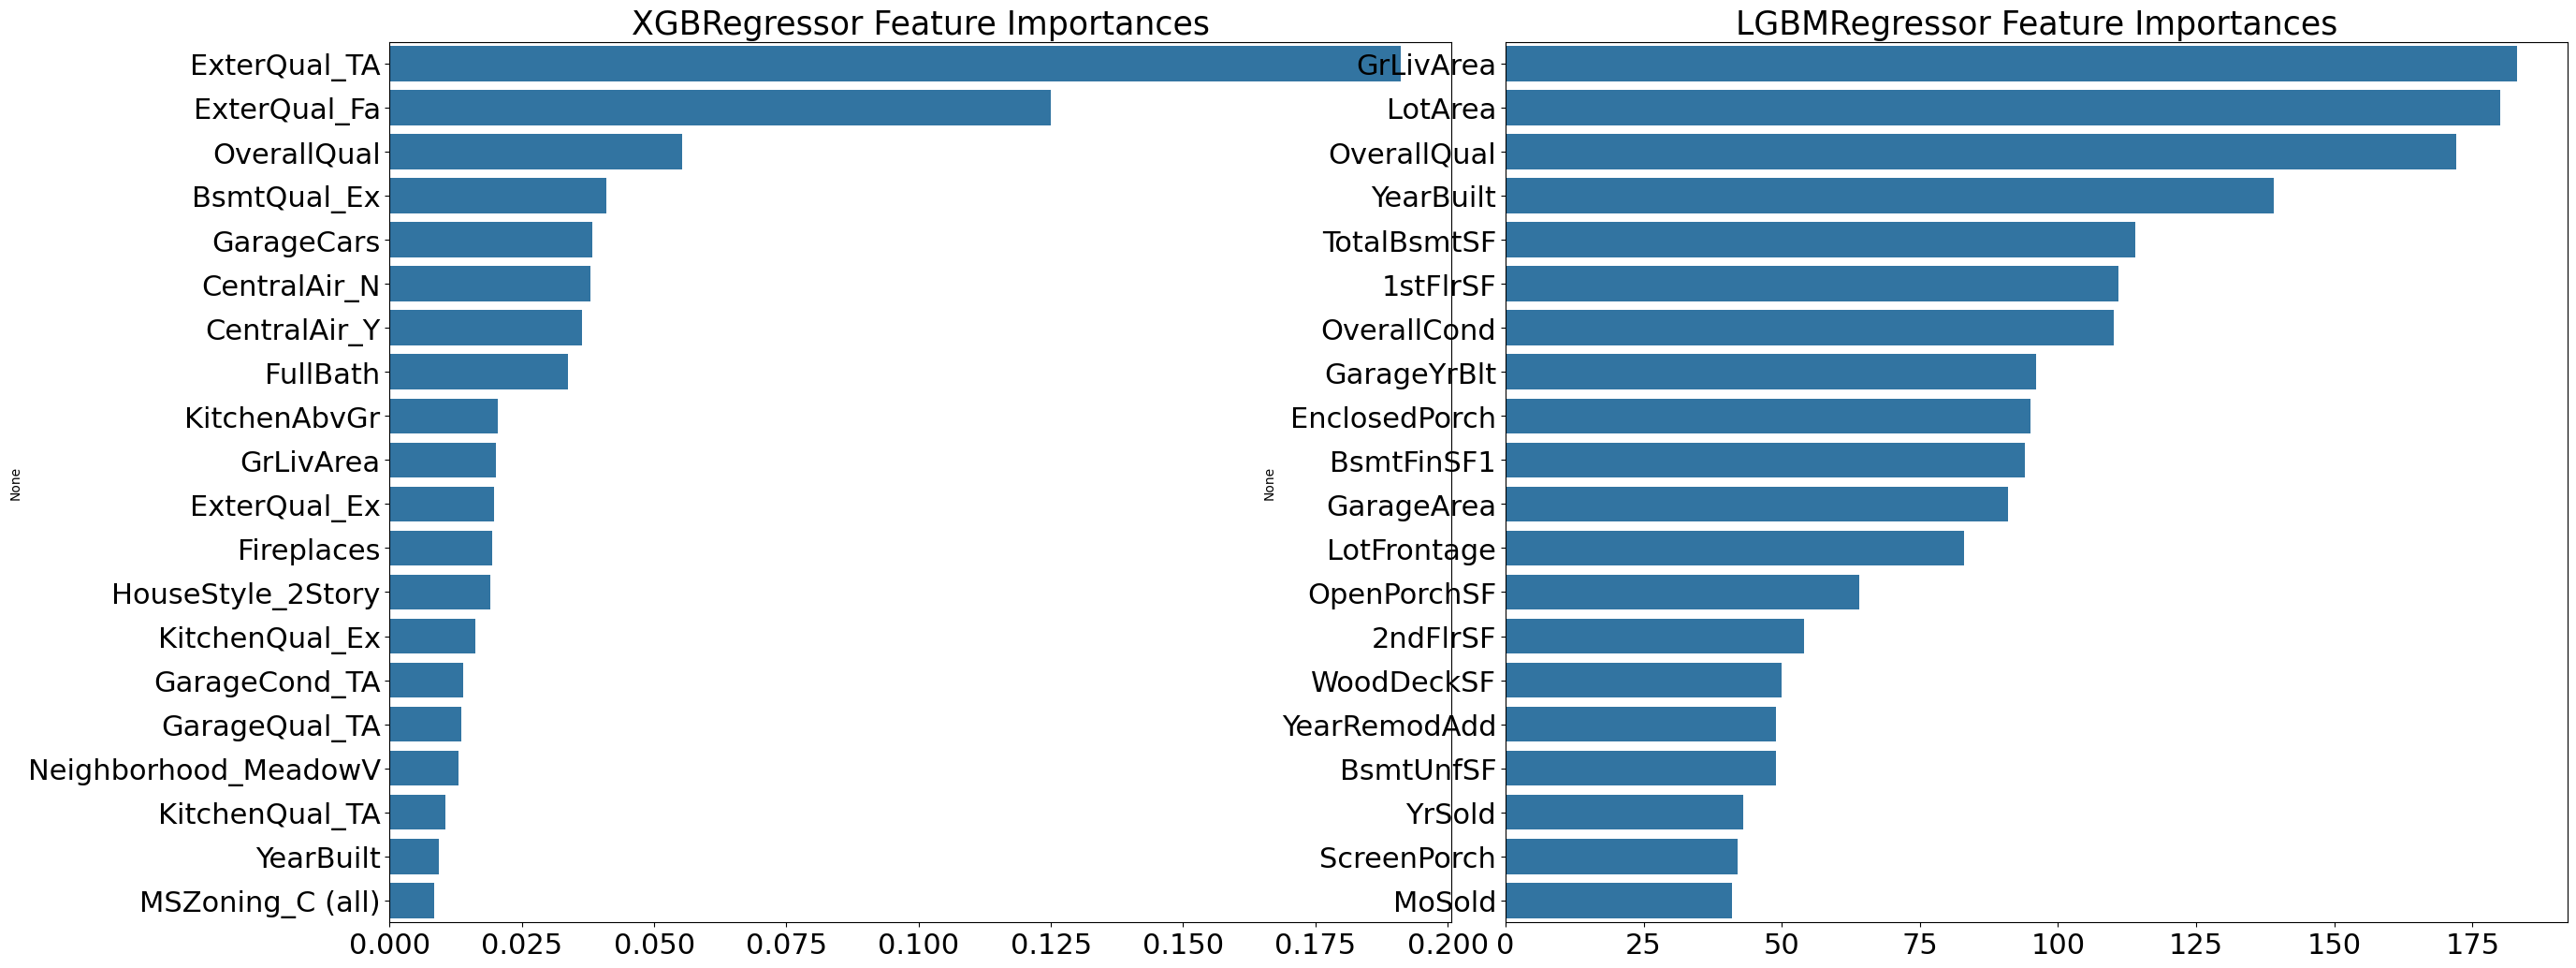

In [80]:
import matplotlib.pyplot as plt
import seaborn as sns

# 모델의 피처 중요도 상위 20개 추출
def get_top_features(model):
    ftr_importances_values = model.feature_importances_
    ftr_importances = pd.Series(ftr_importances_values, index=X_features.columns)
    ftr_top20 = ftr_importances.sort_values(ascending=False)[:20]
    return ftr_top20

# 두 모델의 피처 중요도를 나란히 시각화
def visualize_ftr_importances(models):
    fig, axs = plt.subplots(figsize=(24, 10), nrows=1, ncols=2)
    fig.tight_layout()
    for i_num, model in enumerate(models):
        ftr_top20 = get_top_features(model)
        axs[i_num].set_title(model.__class__.__name__ + ' Feature Importances', size=25)
        for label in (axs[i_num].get_xticklabels() + axs[i_num].get_yticklabels()):
            label.set_fontsize(22)
        sns.barplot(x=ftr_top20.values, y=ftr_top20.index, ax=axs[i_num])

# 앞에서 만든 XGBoost, LightGBM 모델을 전체 데이터로 학습
# (GridSearchCV의 best_estimator_도 전체 데이터로 재학습되므로 같은 방식)
xgb_reg.fit(X_features, y_target)
lgbm_reg.fit(X_features, y_target)

models = [xgb_reg, lgbm_reg]
visualize_ftr_importances(models)

# **회귀 모델의 예측 결과 혼합을 통한 최종 예측**

개별 회귀 모델의 예측 결괏값을 혼합해 이를 기반으로 최종 회귀 값을 예측
- 가령 A 모델과 B 모델, 두 모델의 예측값이 있다면 A 모델 예측값의 40%, B 모델 예측값의 60%를 더해서 최종 회귀 값으로 예측하는 것
- A 회귀 모델의 예측값이 [100, 80, 60]이고, B 회귀 모델의 예측값이 [120, 80, 50]이라면 최종 회귀 예측값은 [100x0.4 + 120x0.6, 80x0.4 + 80x0.6, 60x0.4 + 50x0.6] = [112, 80, 54]

In [82]:
def get_rmse_pred(preds):
  for key in preds.keys():
    pred_value = preds[key]
    mse = mean_squared_error(y_test, pred_value)
    rmse = np.sqrt(mse)
    print('{0} 모델의 RMSE：{1}'.format(key, rmse))

# 개별 모델의 학습
ridge_reg = Ridge(alpha=8)
ridge_reg.fit(X_train, y_train)
lasso_reg = Lasso(alpha=0.001)
lasso_reg.fit(X_train, y_train)

# 개별 모델 예측
ridge_pred = ridge_reg.predict(X_test)
lasso_pred = lasso_reg.predict(X_test)

# 개별 모델 예측값 혼합으로 최종 예측값 도출
pred = 0.4 * ridge_pred + 0.6 * lasso_pred
preds = {'최종 혼합': pred,
        'Ridge': ridge_pred,
        'Lasso': lasso_pred}

# 최종 혼합 모델, 개별 모델의 RM요 값 출력
get_rmse_pred(preds)



최종 혼합 모델의 RMSE：0.10006075517615193
Ridge 모델의 RMSE：0.10340697165289348
Lasso 모델의 RMSE：0.10024171179335342


# **스태킹 앙상블 모델을 통한 회귀 예측**

스태킹 모델
- 1. 개별적인 기반 모델
- 2. 이 개별 기반 모델의 에측 데이터를 학습 데이터로 만들어서 학습하는 최종 메타 모델


스태킹 모델 핵심 : 여러 개별 모델의 예측 데이터를 각각 스태킹 형태로 결합해 최종 메타 모델의 학습용 피처 데이터 세트와 테스트용 피처 데이터 세트를 만드는 것

최종 메타 모델 = 학습할 피처 데이터 세트는 원본 학습 피처 세트로 학습한 개별 모델의 예측값을 스
태킹 형태로 결합한 것


In [86]:
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error

# 개별 기반 모델에서 최종 메타 모델이 사용할 학습 및 테스트용 데이터를 생성하기 위한 함수.
def get_stacking_base_datasets(model, X_train_n, y_train_n, X_test_n, n_folds ):
  # 지정된 n_folds값으로 KFold 생성.
  kf = KFold(n_splits=n_folds, shuffle=False)
  # 추후에 메타 모델이 사용할 학습 데이터 반환을 위한 넘파이 배열 초기화
  train_fold_pred = np.zeros((X_train_n.shape[0], 1))
  test_pred = np.zeros((X_test_n.shape[0], n_folds))
  print(model.__class__.__name__, 'model 시작')

  for folder_counter, (train_index, valid_index) in enumerate(kf.split(X_train_n)):
    # 입력된 학습 데이터에서 기반 모델이 학습/예측할 폴드 데이터 세트 추출
    print('폴드 세트:', folder_counter, '시작')
    X_tr=X_train_n[train_index]
    y_tr=y_train_n[train_index]
    X_te=X_train_n[valid_index]

    # 폴드 세트 내부에서 다시 만들어진 학습 데이터로 기반 모델의 학습 수행
    model.fit(X_tr, y_tr)
    # 폴드 세트 내부에서 다시 만들어진 검증 데이터로 기반 모델 예측 후 데이터 저장
    train_fold_pred[valid_index, :]=model.predict(X_te).reshape(-1, 1)
    # 입력된 원본 테스트 데이터를 폴드 세트 내 학습된 기반 모델에서 예측 후 데이터 저장.
    test_pred[:, folder_counter]=model.predict(X_test_n)

  # 폴드 세트 내에서 원본 테스트 데이터를 예측한 데이터를 평균하여 테스트 데이터로 생성
  test_pred_mean=np.mean(test_pred, axis=1).reshape(-1, 1)

  # train_fold_pred는 최종 메타 모델이 사용되는 학습 데이터, test_pred_mean은 테스트 데이터
  return train_fold_pred, test_pred_mean

get_stacking_base_datasets()를 모델별로 적용해 메타 모델이 사용할 학습 피처 데이터 세트
와 테스트 피처 데이터 세트를 추출
- 적용할 개별 모델은 릿지, 라쏘, XGBoost, LightGMB의 총 4개

In [87]:
# get_stacking_base_datasets( )는 넘파이 ndarray를 인자로 사용하므로 DataFrame을 넘파이로 변환.
X_train_n = X_train. values
X_test_n = X_test. values
y_train_n = y_train. values

# 각 개별 기반(Base) 모델이 생성한 학습용/테스트용 데이터 반환
ridge_train, ridge_test = get_stacking_base_datasets(ridge_reg, X_train_n, y_train_n, X_test_n, 5)
lasso_train, lasso_test = get_stacking_base_datasets(lasso_reg, X_train_n, y_train_n, X_test_n, 5)
xgb_train, xgb_test = get_stacking_base_datasets(xgb_reg, X_train_n, y_train_n, X_test_n, 5)
lgbm_train, lgbm_test = get_stacking_base_datasets(lgbm_reg, X_train_n, y_train_n, X_test_n, 5)


Ridge model 시작
폴드 세트: 0 시작
폴드 세트: 1 시작
폴드 세트: 2 시작
폴드 세트: 3 시작
폴드 세트: 4 시작
Lasso model 시작
폴드 세트: 0 시작
폴드 세트: 1 시작
폴드 세트: 2 시작
폴드 세트: 3 시작
폴드 세트: 4 시작
XGBRegressor model 시작
폴드 세트: 0 시작
폴드 세트: 1 시작
폴드 세트: 2 시작
폴드 세트: 3 시작
폴드 세트: 4 시작
LGBMRegressor model 시작
폴드 세트: 0 시작
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001008 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2924
[LightGBM] [Info] Number of data points in the train set: 932, number of used features: 156
[LightGBM] [Info] Start training from score 12.035561
폴드 세트: 1 시작
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001105 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2951
[LightGBM] [Info] Number of data points in the train se

각 개별 모델이 반환하는 학습용 피처 데이터와 테스트용 피처 데이터 세트들 결합해 최종 메타 모델에 적용
- 메타 모델은 별도의 라쏘 모델을 이용하며, 최종적으로 예측 및 RMSE를 측정

In [90]:
# 개별 모델이 반환한 학습 및 테스트용 데이터 세트를 스태킹 형태로 결합.
Stack_final_X_train = np.concatenate((ridge_train, lasso_train, xgb_train, lgbm_train), axis=1)
Stack_final_X_test = np.concatenate((ridge_test, lasso_test, xgb_test, lgbm_test), axis=1)

# 최종 메타 모델은 라쏘 모델을 적용.
meta_model_lasso = Lasso(alpha=0.0005)

# 개별 모델 예측값을 기반으로 새롭게 만들어진 학습/테스트 데이터로 메타 모델 예측 및 RMSE 측정.
meta_model_lasso.fit(Stack_final_X_train, y_train)
final = meta_model_lasso.predict(Stack_final_X_test)
mse = mean_squared_error(y_test, final)
rmse = np.sqrt(mse)
print('스태킹 회귀 모델의 최종 RMSE 값은:', rmse)

스태킹 회귀 모델의 최종 RMSE 값은: 0.09663398093186237


현재까지 가장 좋은 성능 평가를 보여줍니다. 스태킹 모델은 분류뿐만 아니라 회귀에서 특히 효과적으로 사용될수 있는 모델이다

# **Summary**
- 선형회귀는 실제값과 예측값의 차이인 오류를 최소로 줄일 수 있는 선형 함수를 찾아서 이 선형 함수에 독립변수(피처)를 입력해 종속변수(타깃값, 예측값)를 예측하는 것이다
  - 이 최적의 선형 함수를 찾기 위해, 예측값 차이의 제곱을 회귀계수 W를 변수로 하는 비용 함수로 만들고
  - 이 비용 함수가 최소가 되는 W 값을 찾아 선형함수 도출
- 실제값과 예측값의 차이를 최소화하는 것에만 초점을 맞춘 단순 선형 회귀는 학습 데이터에 과적합되
는 문제를 수반할 가능성이 높다
- 과적합 문제 해결 = 규제(Regulation)
  - L2 규제를 적용한 릿지
  - L1 규제를 적용한 라쏘
  - L1 에 L2 규제를 결합한 엘라스틱넷
- 선형 회귀를 분류에 적용한 대표적인 모델: 로지스틱 회귀(분류를 위한 알고리즘)
  - 선형 함수 대신 최적의 시그모이드 함수 도출
  - 독립변수(피처)를 이 시그모이드 함수에 입력해 반환된결과를 확률값으로 변환해 예측 레이블 결정
- 회귀트리 : 리프 노드에 속한 데이터 값의
평균값을 구해 회귀 예측값을 계산
  - 결정 트리, 랜덤 포레스트, GBM, XGBoost, LightGBM 모두 회귀 트리를 이용해 회귀를 수행하는 방법을 제공
- 선형 회귀는 데이터 값의 분포도와 인코딩 방법에 많은 영향을 받는다
  - 정규분포(종 모양) 형태 선호
    - 타깃값의 분포도가 왜곡되지 않고 정규분포 형태로 되어야 예측 성능을 저하시키지 않는다
  - 왜곡된 데이터 분포도를 가지고 있을 경우, 로그 변환 적용
    - 카테고리형 데이터가 있을 경우, 레이블 인코딩을 통한 숫자형 변환보다는 원-핫 인코딩으로 변환